# Module 7 — Model Monitoring
MLOps role. After deployment the segmentation can silently go stale: learners change behaviour, courses are
redesigned, the platform changes. This notebook implements the monitoring loop:

1. **Data drift** of every model input: PSI, Kolmogorov–Smirnov, and an **Evidently** DataDriftPreset report
2. **Cluster stability over time**: segment shares per cohort, centroid shift (Hungarian-matched refit), silhouette,
   share of atypical learners
3. **Re-clustering triggers** (GREEN / AMBER / RED) and the decision for each batch
4. A **stress scenario** (simulated platform change) proving the triggers fire
5. Monitoring of live API traffic (prediction log)

Reference = training cohorts 2013B–2014B. Incoming batch = the unseen 2014J cohort.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src")) if (Path.cwd().parent / "src").exists() else sys.path.insert(0, "src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from sklearn.cluster import KMeans
from edtech import config as C, monitoring as MON, modeling as M, utils as U, viz as V
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)

seg = pd.read_parquet(C.PROCESSED / "learner_segments.parquet")
model = joblib.load(C.MODELS / "segmentation_model.joblib")
FEATS = model.features()
m5 = U.load_metrics("m5")
train_sil = m5["temporal"]["silhouette_train"]
ref = seg[seg.split == "train"].reset_index(drop=True)
cur = seg[seg.split == "monitor"].reset_index(drop=True)
pd.DataFrame(MON.TRIGGERS, index=["threshold"]).T

,threshold
psi_feature_red,0.25
psi_feature_amber,0.10
n_features_red,2.00
segment_share_pp_red,10.00
segment_share_pp_amber,5.00
centroid_shift_red,0.50
centroid_shift_amber,0.30
atypical_share_red,0.15
atypical_share_amber,0.08
silhouette_drop_red,0.05


### Trigger definitions
| Signal | AMBER | RED | Rationale |
|---|---|---|---|
| PSI per feature | > 0.10 | > 0.25 (and ≥ 2 features RED) | standard credit-risk / ML monitoring bands |
| Segment share shift | > 5 pp | > 10 pp | a 10 pp move changes staffing of interventions |
| Mean matched centroid shift | > 0.30 SD | > 0.50 SD | personas' meaning changes |
| Atypical learners (beyond training p95 distance) | > 8% | > 15% | expected 5% by construction |
| Silhouette drop vs training | — | > 0.05 | structure weakening |

**Decision rule:** ≥ 2 RED checks → **RE-CLUSTER** (retrain on recent cohorts, re-validate personas);
1 RED or any AMBER → **INVESTIGATE**; otherwise **NO ACTION**.

## 1. Incoming cohort 2014J vs reference

In [2]:
s14 = MON.evaluate(model, ref, cur, train_sil, "2014J incoming cohort")
print("DECISION:", s14["decision"]); s14["checks"]

DECISION: NO ACTION


{'feature_drift': 'GREEN',
 'segment_share': 'GREEN',
 'centroid_shift': 'GREEN',
 'atypical_share': 'GREEN',
 'silhouette': 'GREEN'}

In [3]:
drift14 = pd.DataFrame(s14["feature_drift"]); U.save_table(drift14, "m7_drift_2014J"); drift14

,feature,ref_mean,cur_mean,ref_median,cur_median,psi,ks_stat,ks_pvalue,status
0,recency_fraction,0.2847,0.2945,0.0929,0.1037,0.0696,0.1072,0.0000,GREEN
1,active_day_fraction,0.2375,0.2221,0.1822,0.1711,0.0094,0.0360,0.0000,GREEN
2,clicks_per_active_day,19.2651,19.8173,16.1180,17.5412,0.0191,0.0573,0.0000,GREEN
3,weekly_cv_active_span,1.2535,1.3365,1.1833,1.2656,0.0283,0.0720,0.0000,GREEN
4,deadline_click_ratio,2.5341,2.7223,1.8865,1.8885,0.0284,0.0399,0.0000,GREEN
5,avg_score_scheduled,50.7652,51.2221,61.0909,59.6000,0.0161,0.0252,0.0006,GREEN
6,last_minute_submission_share,0.1815,0.1916,0.0000,0.0000,0.0103,0.0446,0.0000,GREEN
7,video_completion_rate,0.6194,0.6114,0.6393,0.6275,0.0025,0.0230,0.0022,GREEN
8,forum_posts_per_week,0.2472,0.1776,0.0294,0.0256,0.0445,0.1566,0.0000,GREEN
9,night_login_share,0.2892,0.2910,0.1623,0.1646,0.0038,0.0163,0.0653,GREEN


In [4]:
pd.DataFrame(s14["segment_shares"])

,segment_id,reference_share,current_share,shift_pp
0,S0,0.1248,0.1270,0.2168
1,S1,0.3362,0.2927,-4.3475
2,S2,0.3273,0.3765,4.9132
3,S3,0.2116,0.2038,-0.7825


In [5]:
ev14 = MON.evidently_report(ref[ref.active_day_fraction > 0], cur[cur.active_day_fraction > 0], FEATS,
                            C.MONITORING_REPORTS / "evidently_drift_2014J.html")
pd.DataFrame(ev14["metrics"]).head(12)

,metric,value
0,DriftedColumnsCount(drift_share=0.5),"{'count': 2.0, 'share': 0.2}"
1,"ValueDrift(column=recency_fraction,method=Wass...",0.042054
2,"ValueDrift(column=active_day_fraction,method=W...",0.075344
3,"ValueDrift(column=clicks_per_active_day,method...",0.054224
4,"ValueDrift(column=weekly_cv_active_span,method...",0.141251
5,"ValueDrift(column=deadline_click_ratio,method=...",0.114167
6,"ValueDrift(column=avg_score_scheduled,method=W...",0.0396
7,ValueDrift(column=last_minute_submission_share...,0.058646
8,"ValueDrift(column=video_completion_rate,method...",0.042953
9,"ValueDrift(column=forum_posts_per_week,method=...",0.093857


**2014J verdict: NO ACTION.** All PSI values are below 0.10, segment shares move by less than 5 pp, the refitted
centroids sit 0.27 SD from production (below the 0.30 AMBER line) and 4.7% of learners are atypical — exactly the 5%
expected. Note that the KS test rejects "same distribution" for almost every feature (p < 0.05): with ~10,000
learners per batch even negligible differences are "significant". That is why the triggers use **effect sizes**
(PSI, pp shifts, SD shifts) rather than p-values. Evidently, which uses the Wasserstein distance at this sample size,
flags 2 of 10 columns individually but not the dataset (share 0.2 < 0.5).

## 2. Cluster stability over time (all cohorts)
Each presentation is scored with the frozen model; K-Means is also refitted on each cohort alone and matched to the
production centroids to measure how far the "natural" clusters have moved.

In [6]:
rows = []
for p in ["2013B", "2013J", "2014B", "2014J"]:
    b = seg[seg.code_presentation == p]
    ba = b[b.active_day_fraction > 0]
    Z = model.pipeline.transform(ba)
    shift, _ = MON.centroid_shift(model.kmeans.cluster_centers_, Z)
    r = {"presentation": p, "enrollments": len(b), "silhouette": M.internal_scores(Z, model.kmeans.predict(Z))["silhouette"],
         "mean_centroid_shift_sd": shift, "atypical_share": b.loc[b.active_day_fraction > 0, "is_atypical"].mean(),
         "psi_active_day_fraction": MON.psi(ref.loc[ref.active_day_fraction > 0, "active_day_fraction"].to_numpy(), ba.active_day_fraction.to_numpy())}
    r.update(b.persona.value_counts(normalize=True).to_dict())
    rows.append(r)
over_time = pd.DataFrame(rows).round(4); U.save_table(over_time, "m7_stability_over_time"); over_time

,presentation,enrollments,silhouette,mean_centroid_shift_sd,atypical_share,psi_active_day_fraction,Consistent Achievers,Last-minute Crammers,At-risk Disengaged,Non-starters
0,2013B,4684,0.2221,0.3567,0.0441,0.0334,0.4088,0.2639,0.2186,0.1087
1,2013J,8845,0.1986,0.1465,0.0555,0.0022,0.3441,0.3435,0.1949,0.1175
2,2014B,7804,0.1929,0.2505,0.0475,0.0111,0.2836,0.3471,0.2264,0.1429
3,2014J,11260,0.1929,0.2666,0.0470,0.0094,0.2927,0.3765,0.2038,0.1270


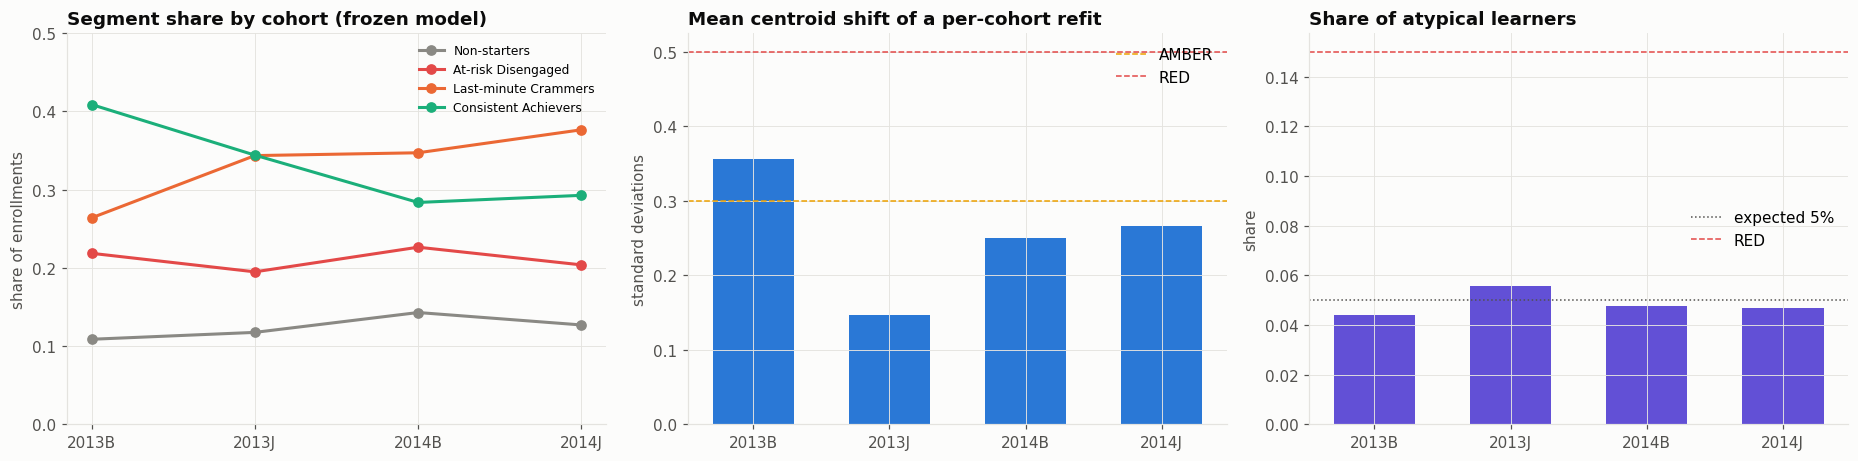

In [7]:
personas = ["Non-starters", "At-risk Disengaged", "Last-minute Crammers", "Consistent Achievers"]
fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
for p in personas:
    ax[0].plot(over_time.presentation, over_time[p], marker="o", color=V.PERSONA_COLORS[p], label=p)
ax[0].set(title="Segment share by cohort (frozen model)", ylabel="share of enrollments", ylim=(0, 0.5)); ax[0].legend(fontsize=8)
ax[1].bar(over_time.presentation, over_time.mean_centroid_shift_sd, color=V.CATEGORICAL[0], width=0.6)
ax[1].axhline(MON.TRIGGERS["centroid_shift_amber"], color=V.CATEGORICAL[3], ls="--", lw=1, label="AMBER")
ax[1].axhline(MON.TRIGGERS["centroid_shift_red"], color=V.CATEGORICAL[7], ls="--", lw=1, label="RED")
ax[1].set(title="Mean centroid shift of a per-cohort refit", ylabel="standard deviations"); ax[1].legend()
ax[2].bar(over_time.presentation, over_time.atypical_share, color=V.CATEGORICAL[6], width=0.6)
ax[2].axhline(0.05, color=V.TEXT2, ls=":", lw=1, label="expected 5%")
ax[2].axhline(MON.TRIGGERS["atypical_share_red"], color=V.CATEGORICAL[7], ls="--", lw=1, label="RED")
ax[2].set(title="Share of atypical learners", ylabel="share"); ax[2].legend()
fig.tight_layout(); V.save(fig, "m7_stability_over_time"); plt.show()

The production segmentation is **stable across all four cohorts** (silhouette 0.19–0.22, atypical share 4–6%,
refit centroids within 0.15–0.36 SD). There is, however, a slow **trend**: the Consistent Achiever share falls from
41% (2013B) to 29% (2014J) while Last-minute Crammers grow from 26% to 38%. Each cohort is within tolerance of the
pooled reference, but the trend means the next cohort could breach the 10 pp threshold. Monitoring therefore also
tracks the share series itself; the playbook asks for an investigation when the same segment moves in the same
direction for three consecutive cohorts.

## 3. Stress scenario — simulated platform change
To demonstrate the triggers end-to-end we apply a documented shock to the 2014J batch: less frequent study
(active-day fraction × 0.55–0.8), more night logins (+25 pp), more last-minute submissions (×1.8 + 10 pp),
stronger deadline concentration (×1.3–1.9), lower video completion (−15 pp) and later drop-off (+10 pp recency).

In [8]:
stress = MON.simulate_drift(cur, np.random.default_rng(C.SEED))
s_stress = MON.evaluate(model, ref, stress, train_sil, "stress scenario (simulated)")
print("DECISION:", s_stress["decision"]); s_stress["checks"]

DECISION: RE-CLUSTER


{'feature_drift': 'RED',
 'segment_share': 'RED',
 'centroid_shift': 'RED',
 'atypical_share': 'AMBER',
 'silhouette': 'GREEN'}

In [9]:
drift_s = pd.DataFrame(s_stress["feature_drift"]); U.save_table(drift_s, "m7_drift_stress"); drift_s

,feature,ref_mean,cur_mean,ref_median,cur_median,psi,ks_stat,ks_pvalue,status
0,recency_fraction,0.2847,0.3905,0.0929,0.2037,4.0347,0.5140,0.0000,RED
1,active_day_fraction,0.2375,0.1497,0.1822,0.1156,0.3026,0.1889,0.0000,RED
2,clicks_per_active_day,19.2651,19.8173,16.1180,17.5412,0.0191,0.0573,0.0000,GREEN
3,weekly_cv_active_span,1.2535,1.3365,1.1833,1.2656,0.0283,0.0720,0.0000,GREEN
4,deadline_click_ratio,2.5341,4.3552,1.8865,3.0288,0.2972,0.2110,0.0000,RED
5,avg_score_scheduled,50.7652,51.2221,61.0909,59.6000,0.0161,0.0252,0.0006,GREEN
6,last_minute_submission_share,0.1815,0.3839,0.0000,0.1000,0.7952,0.5572,0.0000,RED
7,video_completion_rate,0.6194,0.4615,0.6393,0.4775,1.2873,0.3194,0.0000,RED
8,forum_posts_per_week,0.2472,0.1776,0.0294,0.0256,0.0445,0.1566,0.0000,GREEN
9,night_login_share,0.2892,0.5221,0.1623,0.4196,2.8339,0.5259,0.0000,RED


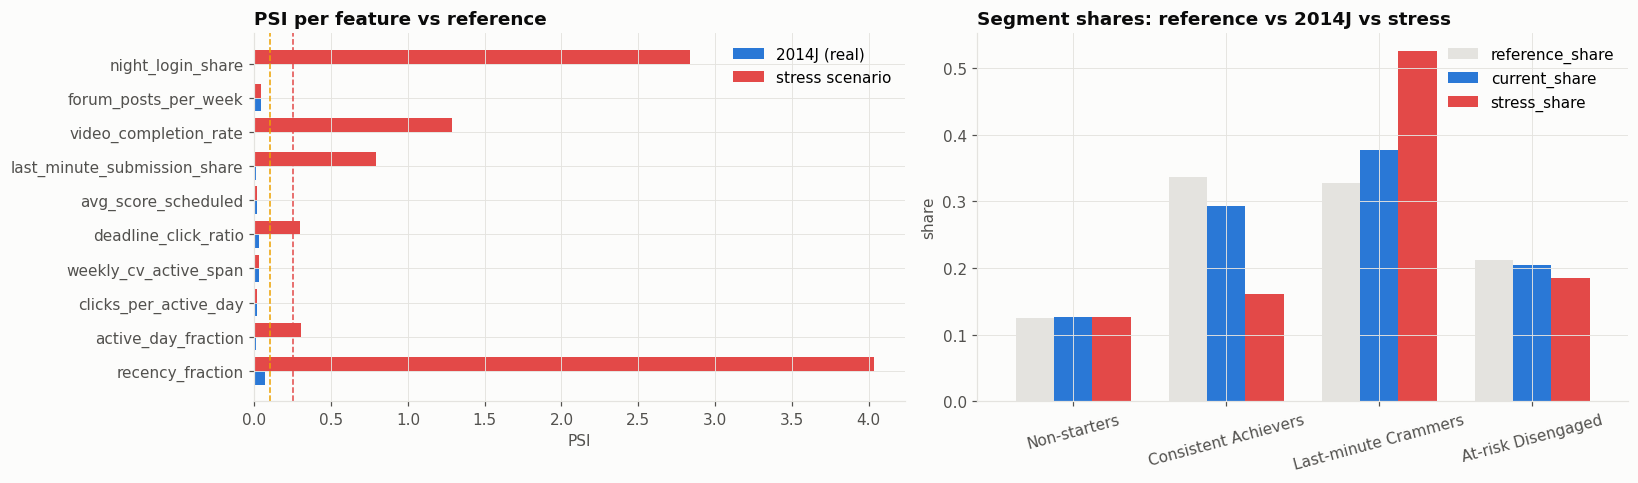

In [10]:
ev_s = MON.evidently_report(ref[ref.active_day_fraction > 0], stress[stress.active_day_fraction > 0], FEATS,
                            C.MONITORING_REPORTS / "evidently_drift_stress_scenario.html")
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
x = np.arange(len(FEATS))
ax[0].barh(x - 0.2, drift14.psi, height=0.4, color=V.CATEGORICAL[0], label="2014J (real)")
ax[0].barh(x + 0.2, drift_s.psi, height=0.4, color=V.CATEGORICAL[7], label="stress scenario")
ax[0].axvline(0.10, color=V.CATEGORICAL[3], ls="--", lw=1); ax[0].axvline(0.25, color=V.CATEGORICAL[7], ls="--", lw=1)
ax[0].set_yticks(x, FEATS); ax[0].set(title="PSI per feature vs reference", xlabel="PSI"); ax[0].legend()
sh = pd.DataFrame(s14["segment_shares"]).set_index("segment_id")[["reference_share", "current_share"]]
sh["stress_share"] = pd.DataFrame(s_stress["segment_shares"]).set_index("segment_id")["current_share"]
names = seg.groupby("segment_id").persona.first()
sh.index = [names[i] for i in sh.index]
sh.plot.bar(ax=ax[1], color=[V.GRID, V.CATEGORICAL[0], V.CATEGORICAL[7]], width=0.75, rot=15)
ax[1].set(title="Segment shares: reference vs 2014J vs stress", ylabel="share")
fig.tight_layout(); V.save(fig, "m7_drift_comparison"); plt.show()

**Stress verdict: RE-CLUSTER.** Six features exceed PSI 0.25, a segment share moves ~20 pp, the refitted centroids
move 1.8 SD and atypical learners rise to 12%. Four of five checks fire, so the rule requires re-clustering: the
frozen personas no longer describe the population and interventions planned on them would be mis-targeted.
The silhouette stays GREEN — a reminder that a model can stay internally "well separated" while becoming wrong for
the business, which is why several independent signals are combined.

## 4. Live API traffic
Every `/predict` call is appended to `data/monitoring/prediction_log.jsonl`. The same PSI checks run on the log
once it holds enough requests (≥ 500); the dashboard shows the latest status.

In [11]:
log_p = C.MONITORING_DATA / "prediction_log.jsonl"
live = pd.read_json(log_p, lines=True) if log_p.exists() else pd.DataFrame()
print(f"logged predictions: {len(live)}")
if len(live) >= 500:
    live_drift = MON.feature_drift(ref[ref.active_day_fraction > 0], live, FEATS); display(live_drift)
else:
    print("Not enough live traffic yet for a statistically meaningful drift check (minimum 500).")

logged predictions: 55
Not enough live traffic yet for a statistically meaningful drift check (minimum 500).


In [12]:
summary = {"triggers": MON.TRIGGERS, "latest": s14, "stress_test": s_stress,
           "over_time": over_time.to_dict("records"),
           "evidently_reports": {"2014J": "evidently_drift_2014J.html", "stress": "evidently_drift_stress_scenario.html"},
           "evidently_2014J": ev14["metrics"][:1], "evidently_stress": ev_s["metrics"][:1]}
(C.MONITORING_DATA / "monitoring_summary.json").write_text(json.dumps(summary, indent=2, default=float))
U.save_metrics("m7", {"decision_2014J": s14["decision"], "checks_2014J": s14["checks"], "decision_stress": s_stress["decision"],
                      "checks_stress": s_stress["checks"], "features_red_2014J": s14["features_red"],
                      "features_red_stress": s_stress["features_red"], "max_shift_pp_2014J": s14["max_segment_shift_pp"],
                      "max_shift_pp_stress": s_stress["max_segment_shift_pp"], "centroid_shift_2014J": s14["mean_centroid_shift_sd"],
                      "centroid_shift_stress": s_stress["mean_centroid_shift_sd"], "atypical_2014J": s14["atypical_share"],
                      "atypical_stress": s_stress["atypical_share"], "over_time": over_time.to_dict("records"),
                      "evidently_2014J": ev14["metrics"][:1], "evidently_stress": ev_s["metrics"][:1]})
{k: (s14[k], s_stress[k]) for k in ["decision", "features_red", "max_segment_shift_pp", "mean_centroid_shift_sd", "atypical_share", "silhouette_current"]}

{'decision': ('NO ACTION', 'RE-CLUSTER'),
 'features_red': (0, 6),
 'max_segment_shift_pp': (4.913212453891308, 19.87768847520569),
 'mean_centroid_shift_sd': (0.2665754346265348, 1.8279523182856068),
 'atypical_share': (0.046998982706002036, 0.12288911495422176),
 'silhouette_current': (0.19348614130529818, 0.1654315103860445)}